# Cue選定制約の比較 v6
固定5ペア・既存1,020候補のみ。距離帯中心は初期700候補から決めた値で固定。許容幅3水準×最小空白3水準×文章タイプ制約2水準の18条件を比較する（従来提案の6条件を含む）。最大採択数をMILPで確定し、その数を維持してjoint目的を多開始局所探索で改善する。API・GPU・埋め込み再計算不要。GitHubの既存結果は変更しない。


In [1]:
!pip -q install scipy
import io, json, re, time, base64, hashlib, itertools, unicodedata
from difflib import SequenceMatcher
import numpy as np, pandas as pd, requests, matplotlib.pyplot as plt
from scipy.optimize import milp, Bounds, LinearConstraint
from google.colab import userdata
from IPython.display import display
REPO='ryouy/GraduationThesis'
RESULT_BRANCH='experiments/cue-selection-luna-v1'
RUN_ID='20261126_cue_constraint_comparison_v6'
ROOT='experiments/2026-11/1126_cue_selection_luna/results/'+RUN_ID
SOURCE_REF='328e2c15a0ec64bbbd68112edf95ec7dd31485e3'
SOURCE='experiments/2026-11/1124_probe_50pairs/results/20261124_probe50_balanced_v5/pair_probe_scores.csv'
SOURCE_BLOB='c0eebc8cbc5b292cab1cc4f7587fb617f16c60b7'
PAIR_IDS=['C01','C27','C35','C23','C37']
API_MODEL='gpt-6-luna'
EMBED='sentence-transformers/all-mpnet-base-v2'
REV='e8c3b32edf5434bc2275fc9bab85f82640a19130'
STYLES={'structure':'physical structure or characteristic properties','action':'typical action or process','situation':'context or circumstances','function':'purpose, role or effect'}
LEVELS={'very_near':'direct distinctive association','near':'strong common association','medium_near':'association through everyday context','medium_far':'indirect but explainable association','far':'weak but meaningful association','unrelated':'no meaningful association with either concept'}
SETTINGS={'A':(.08,.01),'B':(.06,.02),'C':(.04,.03),'D':(.02,.04)}
Y_WIDTHS=[.05,.075,.10]
MAX_CALLS=400
MAX_ATTEMPTS=4
gh=requests.Session()
gh.headers.update({'Authorization':'Bearer '+userdata.get('GITHUB_RESULTS_TOKEN'),'Accept':'application/vnd.github+json'})
BASE=f'https://api.github.com/repos/{REPO}/contents/'
def dump(o):return (json.dumps(o,ensure_ascii=False,sort_keys=True,indent=2,allow_nan=False)+'\n').encode()
def sha(b):
    if not isinstance(b, bytes):raise TypeError('SHA-256 requires file bytes; check source path and branch')
    return hashlib.sha256(b).hexdigest()
def blob(b):return hashlib.sha1(b'blob '+str(len(b)).encode()+b'\0'+b).hexdigest()
def get(path,ref=RESULT_BRANCH):
    r=gh.get(BASE+path,params={'ref':ref},timeout=90)
    if r.status_code==404:return None
    r.raise_for_status(); m=r.json()
    if m.get('encoding')=='base64':b=base64.b64decode(m['content'])
    else:
        r=gh.get(BASE+path,params={'ref':ref},headers={'Accept':'application/vnd.github.raw+json'},timeout=90);r.raise_for_status();b=r.content
    assert blob(b)==m['sha']
    return b
def put(name,b):
    path=ROOT+'/'+name
    old=get(path)
    if old is not None:
        if old!=b:raise RuntimeError('Immutable conflict: '+path)
        return
    for i in range(8):
        try:
            r=gh.put(BASE+path,json={'branch':RESULT_BRANCH,'message':'Cue selection: '+name,'content':base64.b64encode(b).decode()},timeout=90)
        except requests.RequestException:
            old=get(path)
            if old is not None:
                if old!=b:raise RuntimeError('Immutable conflict: '+path)
                return
            time.sleep(min(60,2**i))
            continue
        if r.ok:return
        if r.status_code not in (409,422,429,500,502,503,504):r.raise_for_status()
        old=get(path)
        if old is not None:
            if old!=b:raise RuntimeError('Immutable conflict: '+path)
            return
        time.sleep(min(60,2**i))
    raise RuntimeError('GitHub save retries exhausted: '+path)
def save_df(name,d):put(name,d.to_csv(index=False).encode())

INPUT_ROOT='experiments/2026-11/1126_cue_selection_luna/results/20261126_cue_selection_luna_v1'
INPUT_REF=RESULT_BRANCH
raw=get(INPUT_ROOT+'/cue_candidates_measured.csv',INPUT_REF)
assert sha(raw)=='be48364c113d57171e87b4b61bced56b262ec178d2edfe4afb9c888558c2eb1f'
df=pd.read_csv(io.BytesIO(raw))
assert len(df)==700 and df.quality_pass.sum()==622 and df.id.is_unique
assert set(df['style'])==set(STYLES)
assert set(df['pair'])==set(PAIR_IDS)
assert np.isfinite(df[['d_x','d_y']]).all().all()
df[['d_x','d_y']]=df[['d_x','d_y']].astype('float32')
bounds_raw=get(INPUT_ROOT+'/distance_bounds.csv',INPUT_REF)
assert sha(bounds_raw)=='ce0b57df782ef6b64c8bbd4ddbc529bf9dacd817460fff1087f98d7a6b6cd0b4'
old_bounds=pd.read_csv(io.BytesIO(bounds_raw))
def norm(s):return ' '.join(unicodedata.normalize('NFKC',s).casefold().split())

print('Loaded',len(df),'candidates; quality pass',df.quality_pass.sum())


from scipy.stats import rankdata
from scipy.sparse import csr_matrix
V5='experiments/2026-11/1126_cue_selection_luna/results/20261126_cue_targeted_generation_v5'
def checked(path,expected):
    b=get(path)
    if b is None:raise FileNotFoundError(path)
    assert sha(b)==expected,path
    return pd.read_csv(io.BytesIO(b))
r1=checked(V5+'/round1_measured.csv','3b8b4c3a489269e83fa20312f9b3fd30dfb36d8b7912ed0fa2e872132d177201')
r2=checked(V5+'/round2_measured.csv','d7db13d0c8e64fece6ee4e444822bdeab31860f1cc9fe32578ad44f31aba1976')
v5=checked(V5+'/selected_PROVISIONAL.csv','0927939aac6bbee4aad2ff869d2769e54a5fcd8fcea45901dd4f3e7c7b757483')
v5summary=checked(V5+'/summary.csv','00ee9b39df6f3b32f15b422b834ec3b346681de8e1ae302cca80b23bdb76260a')
df=pd.concat([df,r1,r2],ignore_index=True)
assert len(df)==1020 and df.id.is_unique and df.quality_pass.sum()==911
assert set(df['style'])==set(STYLES) and np.isfinite(df[['d_x','d_y']]).all().all()
df[['d_x','d_y']]=df[['d_x','d_y']].astype('float32')
WIDTHS=[.04,.06,.08];GAPS=[.01,.02,.03];MODES=['per_band','global']
SEEDS=[11,23,37,53,71];STEPS=2000
config={'source_initial_sha':sha(raw),'source_bounds_sha':sha(bounds_raw),'source_v5_manifest':json.loads(get(V5+'/manifest.json')),'widths':WIDTHS,'gaps':GAPS,'modes':MODES,'seeds':SEEDS,'steps':STEPS,'rho_target':.30,'spread_target':.05,'global_style_cap':5,'band_cap':4,'unrelated_per_style':1,'objective':'max(abs(rho)/.30,spread/.05)+.1*(abs(rho)/.30+spread/.05)','status':'exploratory'}
put('config.json',dump(config))
print('Loaded',len(df),'quality pass',df.quality_pass.sum())



Loaded 700 candidates; quality pass 622
Loaded 1020 quality pass 911


In [2]:
# Fixed centers, duplicate conflicts cached per pair, and exact maximum cardinality.
styles=list(STYLES)
def pair_bank(pid):
    g=df[(df.pair==pid)&df.quality_pass].sort_values('id').reset_index(drop=True)
    bb=old_bounds[(old_bounds.pair==pid)&(old_bounds.setting=='C')&(~old_bounds.y_control)].sort_values('band')
    centers=bb.center.to_numpy(dtype=float);assert len(centers)==5
    normed=[norm(s) for s in g.cue]
    conflict=np.zeros((len(g),len(g)),dtype=bool)
    for i,j in itertools.combinations(range(len(g)),2):
        if SequenceMatcher(None,normed[i],normed[j]).ratio()>=.80:conflict[i,j]=conflict[j,i]=True
    return g,centers,conflict
def prepare(bank,width,gap,mode):
    g,centers,cf=bank;g=g.copy()
    mid=(centers[:-1]+centers[1:])/2
    lo=np.maximum(centers-width,np.r_[0,mid+gap/2])
    hi=np.minimum(centers+width,np.r_[mid-gap/2,2])
    g['band']=-1
    for b in range(5):g.loc[(g.related==1)&g.d_x.between(lo[b],hi[b]),'band']=b
    g.loc[g.related==0,'band']=5
    idx=np.flatnonzero(g.band>=0);g=g.iloc[idx].reset_index(drop=True);cf=cf[np.ix_(idx,idx)]
    b=g.band.to_numpy();st=g['style'].map({s:i for i,s in enumerate(styles)}).to_numpy()
    rows=[];caps=[]
    def add(mask,cap):rows.append(mask.astype(float));caps.append(cap)
    for i in range(5):
        add(b==i,4)
        if mode=='per_band':
            for j in range(4):add((b==i)&(st==j),1)
    for j in range(4):
        add((b==5)&(st==j),1)
        if mode=='global':add((b<5)&(st==j),5)
    for i,j in zip(*np.where(np.triu(cf,1))):
        row=np.zeros(len(g));row[i]=row[j]=1;rows.append(row);caps.append(1)
    A=np.array(rows);cap=np.array(caps)
    res=milp(-np.ones(len(g)),integrality=np.ones(len(g)),bounds=Bounds(0,1),constraints=LinearConstraint(csr_matrix(A),0,cap),options={'time_limit':90,'mip_rel_gap':0})
    assert res.success,res.message
    init=np.flatnonzero(res.x>.5)
    return g,centers,lo,hi,cf,A,cap,init
def validate(idx,g,A,cap,n):
    assert len(idx)==n and len(set(idx))==n and n<=24
    assert (A[:,idx].sum(axis=1)<=cap+1e-8).all()
    assert g.iloc[idx].quality_pass.all()
def measures(idx,g):
    z=g.iloc[idx];r=z[z.band<5]
    rho=float(r.d_x.corr(r.d_y,method='spearman'))
    m=r.groupby('band').d_y.mean()
    spread=float(m.max()-m.min()) if len(m)==5 else np.nan
    cross=pd.crosstab(r.band,r['style']).reindex(index=range(5),columns=styles,fill_value=0).to_numpy()
    # Total variation distance to a uniform style distribution per nonempty band.
    counts=cross.sum(axis=1);p=cross/np.maximum(counts[:,None],1)
    imbalance=float(np.mean(.5*np.abs(p[counts>0]-.25).sum(axis=1)))
    # Cramer's V: descriptive, no significance claim.
    expected=np.outer(cross.sum(1),cross.sum(0))/max(cross.sum(),1)
    chi=float(np.divide((cross-expected)**2,expected,out=np.zeros_like(expected,dtype=float),where=expected>0).sum())
    denom=min(int((counts>0).sum())-1,int((cross.sum(0)>0).sum())-1)
    cv=float(np.sqrt(chi/(cross.sum()*denom))) if denom>0 else np.nan
    return rho,spread,imbalance,cv,cross



In [3]:
# Feasible one- and two-candidate exchanges preserve maximum cardinality.
# Two swaps allow changes under saturated global style margins.
def search(prep,seed,mode,start):
    g,centers,lo,hi,cf,A,cap,init=prep
    rng=np.random.default_rng(seed)
    x=g.d_x.to_numpy(dtype=float);y=g.d_y.to_numpy(dtype=float);b=g.band.to_numpy()
    st=g['style'].map({s:i for i,s in enumerate(styles)}).to_numpy()
    pools=[np.flatnonzero(b==k) for k in range(6)]
    def score(idx):
        r=idx[b[idx]<5]
        counts=np.bincount(b[r],minlength=5)
        if (counts==0).any():return 1000+100*sum(counts==0)
        a=rankdata(x[r]);c=rankdata(y[r]);a-=a.mean();c-=c.mean()
        den=np.sqrt((a*a).sum()*(c*c).sum());rho=abs(float(a@c/den)) if den>0 else 1.
        means=np.bincount(b[r],weights=y[r],minlength=5)/counts
        u=rho/.30;v=float(means.max()-means.min())/.05
        return max(u,v)+.1*(u+v)+1e-5*float(np.mean(abs(x[r]-centers[b[r]])))
    cur=start.copy();value=score(cur);best=cur.copy();bestval=value
    for step in range(STEPS):
        prop=cur.copy()
        k=2 if rng.random()<.35 and len(cur)>=2 else 1
        pos=rng.choice(len(cur),k,replace=False)
        for j in pos:
            old=cur[j]
            # Mostly within-band moves; occasional moves across bands for incomplete sets.
            pool=pools[b[old]] if rng.random()<.9 else np.arange(len(g))
            if mode=='per_band' and rng.random()<.9:
                sub=pool[st[pool]==st[old]]
                if len(sub):pool=sub
            prop[j]=rng.choice(pool)
        if len(set(prop))!=len(prop) or (A[:,prop].sum(axis=1)>cap+1e-8).any():continue
        val=score(prop);temp=.5*(.002/.5)**(step/max(STEPS-1,1))
        if val<=value or rng.random()<np.exp(min(0.,(value-val)/temp)):cur=prop;value=val
        if val<bestval-1e-12:best=prop.copy();bestval=val
    return best,bestval
rows=[];chosen=[];runs=[];band_rows=[];bounds_rows=[]
for pid in PAIR_IDS:
    bank=pair_bank(pid)
    for width,gap,mode in itertools.product(WIDTHS,GAPS,MODES):
        prep=prepare(bank,width,gap,mode)
        g,centers,lo,hi,cf,A,cap,init=prep;n=len(init)
        # Reuse v5 start if feasible and equally large; otherwise use exact MILP start.
        old=v5[(v5.pair==pid)&(v5.stage=='round2')]
        ix={v:i for i,v in enumerate(g.id)}
        if len(old)==n and set(old.id)<=set(ix):
            candidate=np.array([ix[v] for v in old.id])
            if (A[:,candidate].sum(axis=1)<=cap+1e-8).all():init=candidate
        validate(init,g,A,cap,n)
        best=None
        for seed in SEEDS:
            idx,val=search(prep,seed,mode,init)
            validate(idx,g,A,cap,n)
            rho,spread,imb,cv,cross=measures(idx,g)
            runs.append(dict(pair=pid,width=width,gap=gap,mode=mode,seed=seed,objective=val,n=n,rho=rho,spread=spread))
            if best is None or val<best[0]:best=(val,idx)
        val,idx=best;z=g.iloc[idx].copy()
        rho,spread,imb,cv,cross=measures(idx,g)
        nr=int((z.band<5).sum());nu=n-nr
        full=n==24 and nr==20 and nu==4
        if full:
            assert (cross.sum(axis=0)==5).all() and (cross.sum(axis=1)==4).all()
        rows.append(dict(pair=pid,x=g.x.iloc[0],y=g.y.iloc[0],width=width,gap=gap,mode=mode,n=n,n_related=nr,n_unrelated=nu,complete=full,rho=rho,abs_rho=abs(rho),spread=spread,style_imbalance=imb,cramers_v=cv,full_target_met=bool(full and abs(rho)<=.30 and spread<=.05),objective=val))
        chosen.append(z.assign(width=width,gap=gap,mode=mode))
        for b in range(5):
            bounds_rows.append(dict(pair=pid,width=width,gap=gap,mode=mode,band=b,center=centers[b],lo=lo[b],hi=hi[b]))
            for j,s in enumerate(styles):band_rows.append(dict(pair=pid,width=width,gap=gap,mode=mode,band=b,style=s,n=int(cross[b,j])))
        print(pid,width,gap,mode,n,round(rho,3),round(spread,3),flush=True)
summary=pd.DataFrame(rows);selected=pd.concat(chosen,ignore_index=True)
assert len(summary)==90
assert not selected.duplicated(['pair','width','gap','mode','id']).any()
# Relaxing a constraint must never reduce the exact maximum count.
for _,g in summary.groupby(['pair','gap','mode']):assert (g.sort_values('width').n.diff().dropna()>=0).all()
for _,g in summary.groupby(['pair','width','mode']):assert (g.sort_values('gap').n.diff().dropna()<=0).all()
for _,g in summary.groupby(['pair','width','gap']):assert g.set_index('mode').loc['global','n']>=g.set_index('mode').loc['per_band','n']
aggregate=summary.groupby(['width','gap','mode']).agg(slots=('n','sum'),complete_pairs=('complete','sum'),mean_abs_rho=('abs_rho','mean'),mean_spread=('spread','mean'),mean_style_imbalance=('style_imbalance','mean'),mean_cramers_v=('cramers_v','mean'),full_targets=('full_target_met','sum')).reset_index()
for name,t in [('summary.csv',summary),('aggregate.csv',aggregate),('selected_PROVISIONAL.csv',selected),('search_runs.csv',pd.DataFrame(runs)),('style_counts.csv',pd.DataFrame(band_rows)),('distance_bounds.csv',pd.DataFrame(bounds_rows))]:save_df(name,t)
display(aggregate.round(4))



C01 0.04 0.01 per_band 23 -0.007 0.001
C01 0.04 0.01 global 24 -0.014 0.001
C01 0.04 0.02 per_band 22 0.009 0.002
C01 0.04 0.02 global 24 0.006 0.007
C01 0.04 0.03 per_band 22 0.003 0.003
C01 0.04 0.03 global 24 0.009 0.011
C01 0.06 0.01 per_band 24 0.0 0.002
C01 0.06 0.01 global 24 0.0 0.002
C01 0.06 0.02 per_band 23 0.009 0.002
C01 0.06 0.02 global 24 -0.017 0.004
C01 0.06 0.03 per_band 23 -0.004 0.003
C01 0.06 0.03 global 24 0.0 0.018
C01 0.08 0.01 per_band 24 0.012 0.002
C01 0.08 0.01 global 24 0.009 0.002
C01 0.08 0.02 per_band 23 0.002 0.001
C01 0.08 0.02 global 24 0.0 0.004
C01 0.08 0.03 per_band 23 0.007 0.001
C01 0.08 0.03 global 24 -0.005 0.017
C27 0.04 0.01 per_band 24 0.269 0.111
C27 0.04 0.01 global 24 0.484 0.112
C27 0.04 0.02 per_band 24 0.307 0.111
C27 0.04 0.02 global 24 0.504 0.12
C27 0.04 0.03 per_band 23 0.34 0.148
C27 0.04 0.03 global 24 0.633 0.128
C27 0.06 0.01 per_band 24 0.286 0.098
C27 0.06 0.01 global 24 0.415 0.102
C27 0.06 0.02 per_band 24 0.295 0.111
C27 0

,width,gap,mode,slots,complete_pairs,mean_abs_rho,mean_spread,mean_style_imbalance,mean_cramers_v,full_targets
0,0.04,0.01,global,120,5,0.3158,0.0721,0.29,0.4593,3
1,0.04,0.01,per_band,119,4,0.2504,0.0768,0.01,0.0258,1
2,0.04,0.02,global,120,5,0.3510,0.0838,0.28,0.4287,2
3,0.04,0.02,per_band,118,4,0.2906,0.0859,0.02,0.0380,0
4,0.04,0.03,global,120,5,0.4039,0.0930,0.25,0.4400,1
5,0.04,0.03,per_band,115,2,0.3328,0.1007,0.05,0.1018,0
6,0.06,0.01,global,120,5,0.2860,0.0697,0.24,0.4111,3
7,0.06,0.01,per_band,120,5,0.2586,0.0743,0.00,0.0000,2
8,0.06,0.02,global,120,5,0.3699,0.0824,0.28,0.4546,1
9,0.06,0.02,per_band,119,4,0.2887,0.0858,0.01,0.0258,0


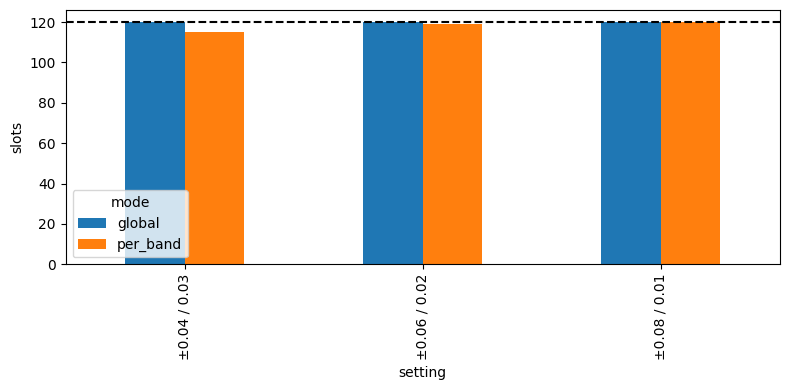

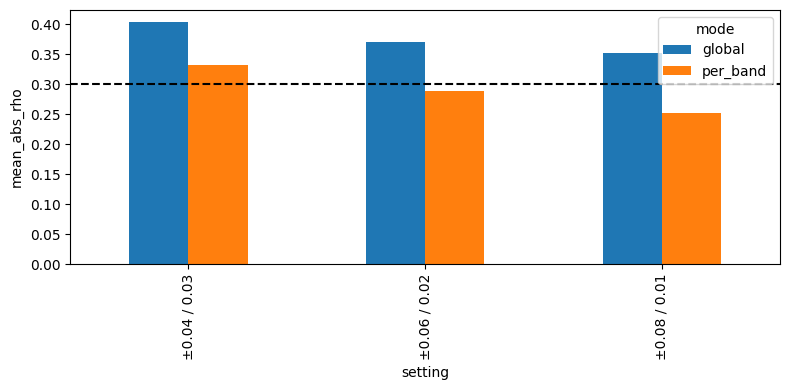

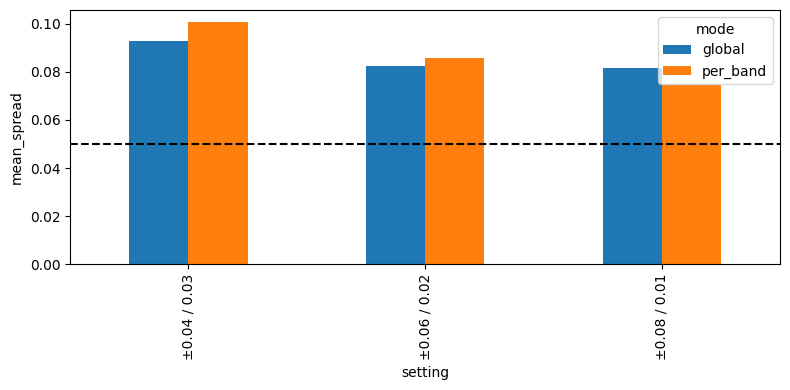

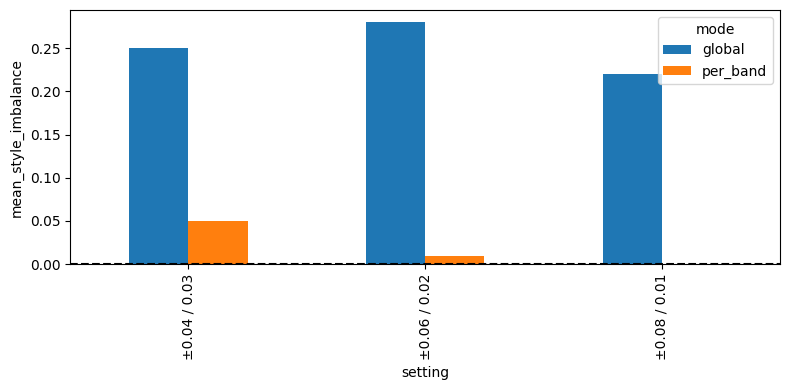

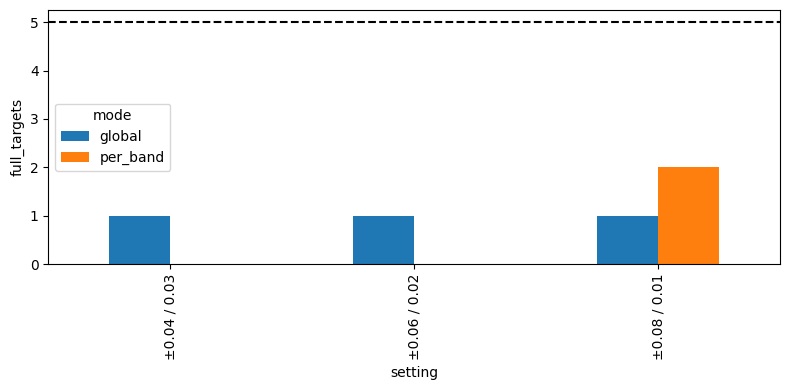

https://github.com/ryouy/GraduationThesis/tree/experiments/cue-selection-luna-v1/experiments/2026-11/1126_cue_selection_luna/results/20261126_cue_constraint_comparison_v6


In [4]:
# Plot the original six paired settings plus full factorial results in CSV.
six=aggregate[((aggregate.width==.04)&(aggregate.gap==.03))|((aggregate.width==.06)&(aggregate.gap==.02))|((aggregate.width==.08)&(aggregate.gap==.01))].copy()
six['setting']=six.apply(lambda r:f"±{r.width:.2f} / {r.gap:.2f}",axis=1)
def figsave(name,fig):
    buf=io.BytesIO();fig.savefig(buf,format='png',dpi=150,bbox_inches='tight');put('figures/'+name+'.png',buf.getvalue());plt.show();plt.close(fig)
for field,target in [('slots',120),('mean_abs_rho',.30),('mean_spread',.05),('mean_style_imbalance',0),('full_targets',5)]:
    fig,ax=plt.subplots(figsize=(8,4));six.pivot(index='setting',columns='mode',values=field).plot.bar(ax=ax);ax.axhline(target,ls='--',color='black');ax.set_ylabel(field);fig.tight_layout();figsave(field,fig)
files=['summary.csv','aggregate.csv','selected_PROVISIONAL.csv','search_runs.csv','style_counts.csv','distance_bounds.csv']
put('manifest.json',dump({'status':'exploratory_not_frozen','config_sha256':sha(dump(config)),'n_candidates':len(df),'n_quality_pass':int(df.quality_pass.sum()),'files':{n:sha(get(ROOT+'/'+n)) for n in files}}))
print('https://github.com/'+REPO+'/tree/'+RESULT_BRANCH+'/'+ROOT)



最大採択数はMILPで証明するがjoint最適化は近似。文章タイプと距離帯の偏りは別途報告し、global方式を採用する場合は本実験の分析で文章タイプを共変量として扱う案も検討する。欠損のある結果と完全セットは区別する。5ペアの探索結果を100ペアに一般化しない。
